<a href="https://colab.research.google.com/github/ibrahimm7359/WIA1007/blob/main/Tutorial3_WIA1007.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Usage & Impact on Students and Professionals
Data exploration using only **NumPy** and **Pandas**.

Dataset = **structured data** (rows and columns, CSV file) - see W03 slides on *Types of Data*.

## 1. Load the dataset and visualize some of it

In [ ]:
import numpy as np
import pandas as pd


from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Datasets/AI_Usage_and_Impact_on_Students_and_Professionals.csv")

df.head()

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes


In [ ]:
# Visualize 1: how many rows and columns?
print("Shape (rows, columns):", df.shape)

# Visualize 2: a quick table of the numeric columns
df.describe()

Shape (rows, columns): (300, 19)


,Productivity_Score,Accuracy_Rating,Satisfaction_Score
count,284.000000,285.000000,293.000000
mean,5.230282,3.428070,6.146758
std,1.817193,0.855338,1.517805
min,1.600000,2.000000,3.000000
25%,3.900000,3.000000,5.000000
50%,5.000000,4.000000,6.000000
75%,6.500000,4.000000,7.000000
max,10.000000,5.000000,10.000000


<Axes: title={'center': 'AI tools used'}, xlabel='AI_Tool'>

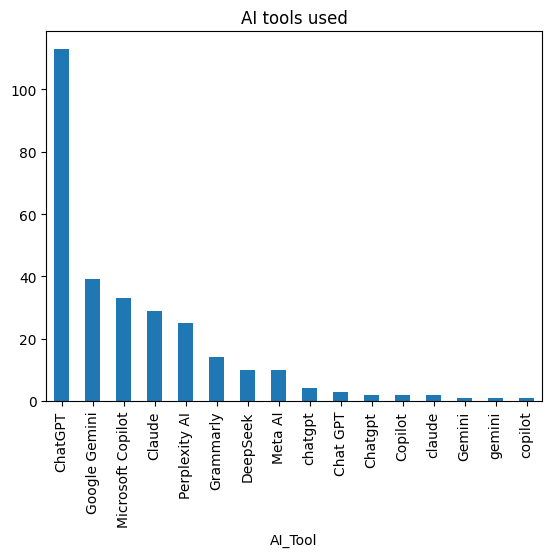

In [ ]:
# Visualize 3: bar chart - which AI tool is used most?
df["AI_Tool"].value_counts().plot(kind="bar", title="AI tools used")

<Axes: title={'center': 'AI purpose'}, xlabel='AI_Purpose'>

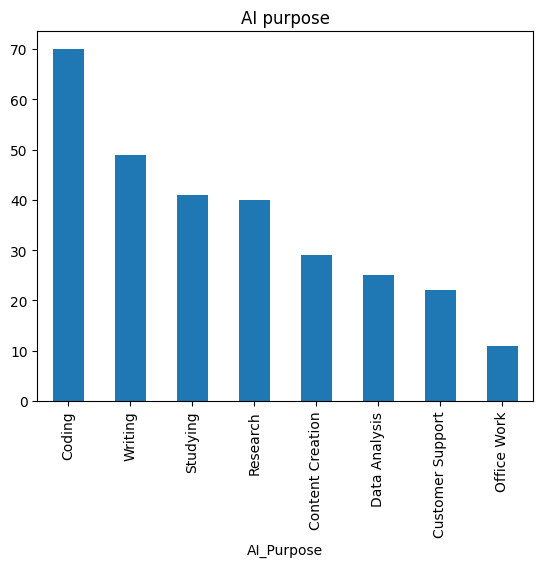

In [ ]:
# Visualize 4: bar chart - what do people use AI for?
df["AI_Purpose"].value_counts().plot(kind="bar", title="AI purpose")

## 2. Is the data good? Does it have enough samples?


In [ ]:
# --- Check A: duplicate rows ---
print("Duplicate rows:", df.duplicated().sum())
print("Unique User_IDs:", df["User_ID"].nunique(), "out of", len(df), "rows")

Duplicate rows: 12
Unique User_IDs: 288 out of 300 rows


In [ ]:
# --- Check B: inconsistent labels (same thing written in different ways) ---
print(df["Gender"].value_counts())
print()
print(df["AI_Tool"].value_counts())

Gender
Male          122
Female        105
male           12
Other          12
M              11
F              10
MALE            6
FEMALE          5
other           3
female          3
Non-binary      1
Name: count, dtype: int64

AI_Tool
ChatGPT              113
Google Gemini         39
Microsoft Copilot     33
Claude                29
Perplexity AI         25
Grammarly             14
DeepSeek              10
Meta AI               10
chatgpt                4
Chat GPT               3
Chatgpt                2
Copilot                2
claude                 2
Gemini                 1
gemini                 1
copilot                1
Name: count, dtype: int64


In [ ]:
# --- Check C: numbers stored as text, e.g. '2 hrs', '$1,884', '23 yrs' ---
# Look at a few values from these columns
for col in ["Age", "Monthly_Income", "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost"]:
    print(col, "->", df[col].dropna().unique()[:12])

Age -> ['30' '17' '35' '19' '32' '16' '40' '36' '22' '21' '28' '16 yrs']
Monthly_Income -> ['5421' '8903' '402' '1367' '438' '774' '4466' '486' '132' '1595' '856'
 '547']
AI_Usage_Hours_Per_Day -> ['2 hrs' '5.7' '1 hrs' '1.7' '4.1' '1.5' '1.2' '2' '1.6 hrs' '2.7' '5'
 '0.8']
Monthly_AI_Cost -> ['0' '20' '30' '10' '$0 ' '50' '$30 ' '25' '$25 ' '$50 ' '100' '$20 ']


In [ ]:
# --- Check D: strange values (outliers) ---
# Convert to numbers just for checking (errors="coerce" turns bad text into NaN)
age = pd.to_numeric(df["Age"].str.replace(" yrs", ""), errors="coerce")
income = pd.to_numeric(df["Monthly_Income"].str.replace("$", "").str.replace(",", ""), errors="coerce")
ai_hours = pd.to_numeric(df["AI_Usage_Hours_Per_Day"].str.replace(" hrs", ""), errors="coerce")

print("Age          min / max:", age.min(), "/", age.max())
print("Income       min / max:", income.min(), "/", income.max())
print("AI hrs/day   min / max:", ai_hours.min(), "/", ai_hours.max())

Age          min / max: 16.0 / 97.0
Income       min / max: 0.0 / 250000.0
AI hrs/day   min / max: 0.5 / 23.0


In [ ]:
# --- Check E: how many rows are COMPLETE (no missing value at all)? ---
complete_rows = df.dropna().shape[0]
print("Rows with no missing values:", complete_rows, "out of", len(df))
print("Percent of rows we would lose if we drop missing rows:",
      round((len(df) - complete_rows) / len(df) * 100, 1), "%")

Rows with no missing values: 149 out of 300
Percent of rows we would lose if we drop missing rows: 50.3 %


**Answer (Q2):** The data is *usable but messy*.
- Good: 300 rows, a nice mix of students/professionals, 20 countries, 16 tools, and the scores look realistic.
- Bad: 12 duplicate rows; labels written in many ways (Male / male / M / MALE, ChatGPT / Chat GPT / chatgpt); numbers stored as text ("2 hrs", "$1,884", "23 yrs"); missing values in 17 of 19 columns; and strange values (age 97, income 250000, 23 AI hours/day).
- Samples: 300 rows is **small but OK for learning/exploration**. After removing duplicates and rows with missing values only 149 of the 300 rows are left (50% lost), which is **not enough for a reliable machine-learning model** - so we should *clean and fill* rather than delete.

## 3. How many features does it have? Is it enough?

In [ ]:
n_columns = df.shape[1]
print("Total columns:", n_columns)
print()
print(list(df.columns))

Total columns: 19

['User_ID', 'Age', 'Gender', 'Country', 'User_Type', 'Education_Level', 'Profession', 'Monthly_Income', 'AI_Tool', 'AI_Purpose', 'AI_Usage_Hours_Per_Day', 'Tasks_Performed', 'Monthly_AI_Cost', 'Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day', 'Would_Recommend']


In [ ]:
# Some columns are NOT useful as features:
#   User_ID          -> just an ID (nominal), no meaning for prediction
#   Tasks_Performed  -> long free text (unstructured data)
#   Profession       -> 126 different values, too many categories
not_useful = ["User_ID", "Tasks_Performed", "Profession"]
print("Unique Professions:", df["Profession"].nunique())
print("Unique Tasks_Performed:", df["Tasks_Performed"].nunique())

# 19 columns - 1 target - 3 not useful = usable features
usable_features = n_columns - 1 - len(not_useful)
print("Usable features (approx.):", usable_features)

Unique Professions: 126
Unique Tasks_Performed: 270
Usable features (approx.): 15


**Answer (Q3):** The dataset has **19 columns**. One will be the target and 3 are not useful (`User_ID`, `Tasks_Performed`, `Profession`), so about **15 usable features**. That is **enough variety** (demographics, tool, purpose, usage, cost, scores) to answer simple questions. But it is a lot of features for only 300 rows.

## 4. How many samples (observations) does it have? Is it enough?

In [ ]:
n_rows = df.shape[0]
print("Total rows (samples):", n_rows)
print("After removing duplicates:", df.drop_duplicates().shape[0])
print("Rows with no missing values:", df.dropna().shape[0])

Total rows (samples): 300
After removing duplicates: 288
Rows with no missing values: 149


In [ ]:
# Rule of thumb: about 10 samples for every feature
usable_features = 15
print("Samples per feature (all rows):", n_rows / usable_features)
print("Samples per feature (complete rows only):", df.dropna().shape[0] / usable_features)

Samples per feature (all rows): 20.0
Samples per feature (complete rows only): 9.933333333333334


In [ ]:
# Are the groups big enough to compare? Count samples in each group
print(df["User_Type"].value_counts())
print()
print(df["Would_Recommend"].value_counts())
print()
print(df["Country"].value_counts().tail(5))   # smallest countries

User_Type
Student         158
Professional    142
Name: count, dtype: int64

Would_Recommend
Yes      178
No        73
Maybe     44
Name: count, dtype: int64

Country
france                      1
U.K.                        1
United States of America    1
philippines                 1
australia                   1
Name: count, dtype: int64


**Answer (Q4):** **300 samples** (288 unique users). This is *enough for exploring and simple comparisons* (students vs professionals, which tool, etc.), but *borderline for machine learning*: 300 / 15 features = 20 samples per feature, and if we delete rows with missing values only 149 rows remain (about 10 per feature). Small groups (e.g. Kenya = 6 rows) are too small to make conclusions about.

## 5. What data types does the dataset consist of?

In [ ]:
# Pandas data types
print(df.dtypes)

User_ID                         object
Age                             object
Gender                          object
Country                         object
User_Type                       object
Education_Level                 object
Profession                      object
Monthly_Income                  object
AI_Tool                         object
AI_Purpose                      object
AI_Usage_Hours_Per_Day          object
Tasks_Performed                 object
Monthly_AI_Cost                 object
Productivity_Score             float64
Accuracy_Rating                float64
Satisfaction_Score             float64
Time_Saved_Hours_Per_Week       object
Work_or_Study_Hours_Per_Day     object
Would_Recommend                 object
dtype: object


In [ ]:
# How many columns of each pandas type?
print(df.dtypes.value_counts())

object     16
float64     3
Name: count, dtype: int64


**Answer (Q5):** Pandas says almost everything is str/object (text) and only 3 columns are float64.



## 6. How many columns have null values? Which columns and which rows?

In [ ]:
# Count of missing values in every column
missing_per_column = df.isnull().sum()
print(missing_per_column)

User_ID                         0
Age                            23
Gender                         10
Country                        10
User_Type                       0
Education_Level                13
Profession                     15
Monthly_Income                 10
AI_Tool                        11
AI_Purpose                     13
AI_Usage_Hours_Per_Day          7
Tasks_Performed                18
Monthly_AI_Cost                12
Productivity_Score             16
Accuracy_Rating                15
Satisfaction_Score              7
Time_Saved_Hours_Per_Week      10
Work_or_Study_Hours_Per_Day     9
Would_Recommend                 5
dtype: int64


In [ ]:
# How many columns have at least one missing value?
columns_with_nulls = missing_per_column[missing_per_column > 0]
print("Columns with null values:", len(columns_with_nulls), "out of", df.shape[1])
print()
print(columns_with_nulls.sort_values(ascending=False))

Columns with null values: 17 out of 19

Age                            23
Tasks_Performed                18
Productivity_Score             16
Profession                     15
Accuracy_Rating                15
AI_Purpose                     13
Education_Level                13
Monthly_AI_Cost                12
AI_Tool                        11
Time_Saved_Hours_Per_Week      10
Monthly_Income                 10
Country                        10
Gender                         10
Work_or_Study_Hours_Per_Day     9
AI_Usage_Hours_Per_Day          7
Satisfaction_Score              7
Would_Recommend                 5
dtype: int64


In [ ]:
# Which rows? Print the row numbers (index) for each column that has nulls
for col in columns_with_nulls.index:
    rows = df[df[col].isnull()].index.tolist()
    print(col, "->", len(rows), "rows:", rows)
    print()

Age -> 23 rows: [29, 49, 52, 74, 78, 95, 96, 123, 151, 166, 194, 207, 213, 218, 220, 222, 232, 233, 236, 239, 263, 264, 295]

Gender -> 10 rows: [5, 23, 38, 43, 53, 70, 99, 117, 127, 131]

Country -> 10 rows: [36, 66, 128, 155, 173, 176, 177, 193, 212, 240]

Education_Level -> 13 rows: [2, 24, 29, 94, 131, 132, 159, 169, 182, 188, 242, 271, 281]

Profession -> 15 rows: [9, 15, 36, 43, 49, 115, 170, 189, 195, 207, 245, 263, 279, 293, 295]

Monthly_Income -> 10 rows: [22, 28, 39, 74, 111, 193, 207, 225, 250, 296]

AI_Tool -> 11 rows: [33, 37, 72, 76, 81, 113, 126, 161, 207, 251, 280]

AI_Purpose -> 13 rows: [4, 31, 58, 73, 112, 125, 127, 142, 160, 165, 168, 183, 295]

AI_Usage_Hours_Per_Day -> 7 rows: [48, 60, 94, 174, 249, 252, 270]

Tasks_Performed -> 18 rows: [2, 15, 22, 35, 60, 75, 76, 78, 98, 105, 123, 149, 170, 171, 182, 237, 261, 291]

Monthly_AI_Cost -> 12 rows: [0, 22, 49, 54, 65, 115, 158, 189, 210, 217, 246, 255]

Productivity_Score -> 16 rows: [9, 10, 15, 38, 77, 97, 112, 135

**Answer (Q6):** **17 out of 19 columns** have null values. Only User_ID and User_Type are complete. The most affected: Age (23), Tasks_Performed (18), Productivity_Score (16), Profession (15), Accuracy_Rating (15). The code above prints the exact row numbers for every column. In total **151 of 300 rows** have at least one missing value.

## 7. Which columns are the features and which is the target?


In [ ]:
target = "Productivity_Score"

# Features = columns we think can explain the target
features = [
    "Age", "Gender", "Country", "User_Type", "Education_Level",
    "Monthly_Income", "AI_Tool", "AI_Purpose",
    "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost",
    "Work_or_Study_Hours_Per_Day",
]

# Columns we leave out
left_out = [c for c in df.columns if c not in features and c != target]

print("TARGET  :", target)
print("FEATURES:", features)
print("LEFT OUT:", left_out)

TARGET  : Productivity_Score
FEATURES: ['Age', 'Gender', 'Country', 'User_Type', 'Education_Level', 'Monthly_Income', 'AI_Tool', 'AI_Purpose', 'AI_Usage_Hours_Per_Day', 'Monthly_AI_Cost', 'Work_or_Study_Hours_Per_Day']
LEFT OUT: ['User_ID', 'Profession', 'Tasks_Performed', 'Accuracy_Rating', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week', 'Would_Recommend']


**Answer (Q7):**
- **Target:** `Productivity_Score` (alternative: `Would_Recommend` if we want Yes/No/Maybe).
- **Features:** Age, Gender, Country, User_Type, Education_Level, Monthly_Income, AI_Tool, AI_Purpose, AI_Usage_Hours_Per_Day, Monthly_AI_Cost, Work_or_Study_Hours_Per_Day.
- **Left out:** `User_ID` (just an ID), `Tasks_Performed` (free text), `Profession` (126 values). Also `Satisfaction_Score`, `Accuracy_Rating`, `Time_Saved_Hours_Per_Week` and `Would_Recommend` - these are *results* of using AI (like the target), not causes, so using them as features would be unfair.

## 8. Does it have missing values? Which column, which row?
Same check as Q6, but now focused on the **features and target** we chose in Q7.

In [ ]:
columns_to_check = features + [target]

# Missing values in features + target
print(df[columns_to_check].isnull().sum())

Age                            23
Gender                         10
Country                        10
User_Type                       0
Education_Level                13
Monthly_Income                 10
AI_Tool                        11
AI_Purpose                     13
AI_Usage_Hours_Per_Day          7
Monthly_AI_Cost                12
Work_or_Study_Hours_Per_Day     9
Productivity_Score             16
dtype: int64


In [ ]:
# Missing values in the TARGET - these rows cannot be used for training
target_missing_rows = df[df[target].isnull()].index.tolist()
print("Rows where", target, "is missing:", len(target_missing_rows))
print(target_missing_rows)

Rows where Productivity_Score is missing: 16
[9, 10, 15, 38, 77, 97, 112, 135, 147, 159, 170, 171, 253, 260, 271, 286]


In [ ]:
# Rows that are complete for features + target
complete = df[columns_to_check].dropna()
print("Complete rows (features + target):", complete.shape[0], "out of", len(df))

Complete rows (features + target): 183 out of 300


In [ ]:
# Simple ways to handle missing values
df_clean = df.drop_duplicates().copy()       # 1) remove duplicate rows

# 2) Drop rows where the TARGET is missing
df_clean = df_clean.dropna(subset=[target])

# 3) Fill missing numbers with the median (middle value)
for col in ["Age", "Monthly_Income", "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost", "Work_or_Study_Hours_Per_Day"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 4) Fill missing categories with the most common value (mode)
for col in ["Gender", "Country", "Education_Level", "AI_Tool", "AI_Purpose"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Rows kept:", len(df_clean), "(instead of losing about half the data)")
print("Missing values left in features:", df_clean[features].isnull().sum().sum())

Rows kept: 274 (instead of losing about half the data)
Missing values left in features: 0


**Answer (Q8):** Yes. Every feature has some missing values (see table above); the target `Productivity_Score` is missing in 16 rows (they must be removed). Instead of deleting every row with a gap (which would lose half the data), we remove duplicates, drop rows with no target, and fill gaps with the **median** (numbers) or **mode** (categories).

## 9. What questions can / should we ask? Does the dataset suit them?

In [ ]:
# Example question 1: Do people who use AI more hours per day also report higher productivity?
print(df_clean[["AI_Usage_Hours_Per_Day", "Productivity_Score"]].corr())

                        AI_Usage_Hours_Per_Day  Productivity_Score
AI_Usage_Hours_Per_Day                1.000000            0.643852
Productivity_Score                    0.643852            1.000000


In [ ]:
# Example question 2: Do students and professionals get the same benefit?
df_clean.groupby("User_Type")[["Productivity_Score", "Time_Saved_Hours_Per_Week", "Satisfaction_Score"]].mean()

,Productivity_Score,Time_Saved_Hours_Per_Week,Satisfaction_Score
User_Type,,,
Professional,5.281679,5.538710,6.056000
Student,5.192308,6.139286,6.232394


In [ ]:
# Example question 3: Which AI tool gets the best productivity? (only tools with 20+ users)
tool_counts = df_clean["AI_Tool"].value_counts()
big_tools = tool_counts[tool_counts >= 20].index
df_clean[df_clean["AI_Tool"].isin(big_tools)].groupby("AI_Tool")["Productivity_Score"].mean().sort_values(ascending=False)

,Productivity_Score
AI_Tool,
Microsoft Copilot,5.425000
ChatGPT,5.323478
Claude,5.278571
Google Gemini,5.041667
Perplexity AI,4.640000


In [ ]:
# Example question 4: Does paying for AI help? (cost 0 vs cost > 0)
paid = df_clean["Monthly_AI_Cost"] > 0
print("Free users - average productivity:", round(df_clean[~paid]["Productivity_Score"].mean(), 2))
print("Paid users - average productivity:", round(df_clean[paid]["Productivity_Score"].mean(), 2))

Free users - average productivity: 5.38
Paid users - average productivity: 5.05


**Answer (Q9):**

Questions that **suit** this dataset (good):
1. Does more daily AI usage go with higher productivity? *(regression / correlation)*
2. Do students and professionals benefit differently? *(group comparison)*
3. Which AI tool or purpose is linked to the best productivity / satisfaction?
4. Do paid AI users report better results than free users?
5. Can we predict Would_Recommend (Yes / No / Maybe)? *(classification)*

Questions that **do not suit** it (too big for this data):
- "Does AI *cause* higher productivity?" - the scores are self-reported, so we only see *relationships*, not cause.
- Conclusions for a single country or a rare tool - groups have too few rows (e.g. Kenya = 6).
- Anything using the Tasks_Performed text - that needs text-processing tools (unstructured data).

**Verdict:** the dataset is **good for exploration and simple questions**, and **only fair for building a prediction model** because it has few rows, many missing values and messy labels.